# 02 - Exploratory Data Analysis

EDA of the 25-second labeled feature set. This notebook highlights class imbalance and the market features associated with labeled pump windows.

In [17]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd()
if not (ROOT / 'labeled_features').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'labeled_features' / 'features_25S.csv.gz'
OUTPUT_DIR = ROOT / 'output'
OUTPUT_DIR.mkdir(exist_ok=True)

FEATURES = ['std_rush_order', 'avg_rush_order', 'std_trades', 'std_volume', 'avg_volume', 'std_price', 'avg_price', 'avg_price_max']

In [18]:
data = pd.read_csv(DATA_PATH, parse_dates=['date'])
data['gt'] = data['gt'].astype(int)
print(f'Observations: {len(data):,}')
display(data['gt'].value_counts().rename(index={0: 'Normal', 1: 'Pump'}).to_frame('observations'))
display(data.groupby('gt')[FEATURES].median().T)

Observations: 482,157


,observations
gt,
Normal,481840
Pump,317


gt,0,1
std_rush_order,0.0,0.512
avg_rush_order,0.0,0.090
std_trades,0.0,0.856
std_volume,0.0,1.234
avg_volume,0.0,0.214
std_price,0.0,0.008
avg_price,-0.0,0.008
avg_price_max,0.0,0.013


## Class distribution

The positive class is rare, so recall, precision, ROC-AUC, and average precision will be reported for the classifier instead of relying on accuracy.

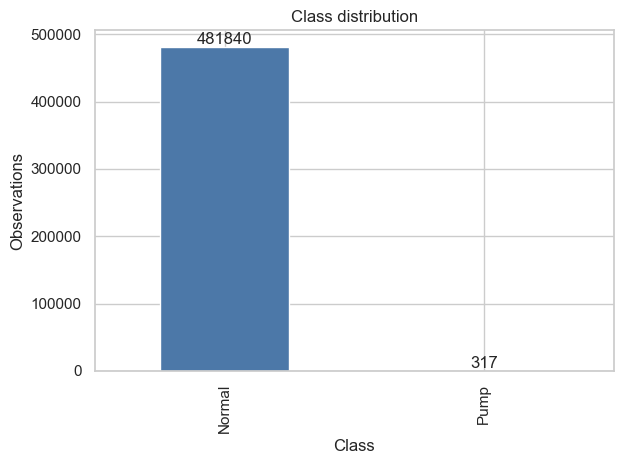

In [19]:
ax = data['gt'].value_counts().sort_index().rename(index={0: 'Normal', 1: 'Pump'}).plot.bar(color=['#4C78A8', '#E45756'])
ax.set(title='Class distribution', xlabel='Class', ylabel='Observations')
ax.bar_label(ax.containers[0], fmt='%d')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=160)
plt.show()

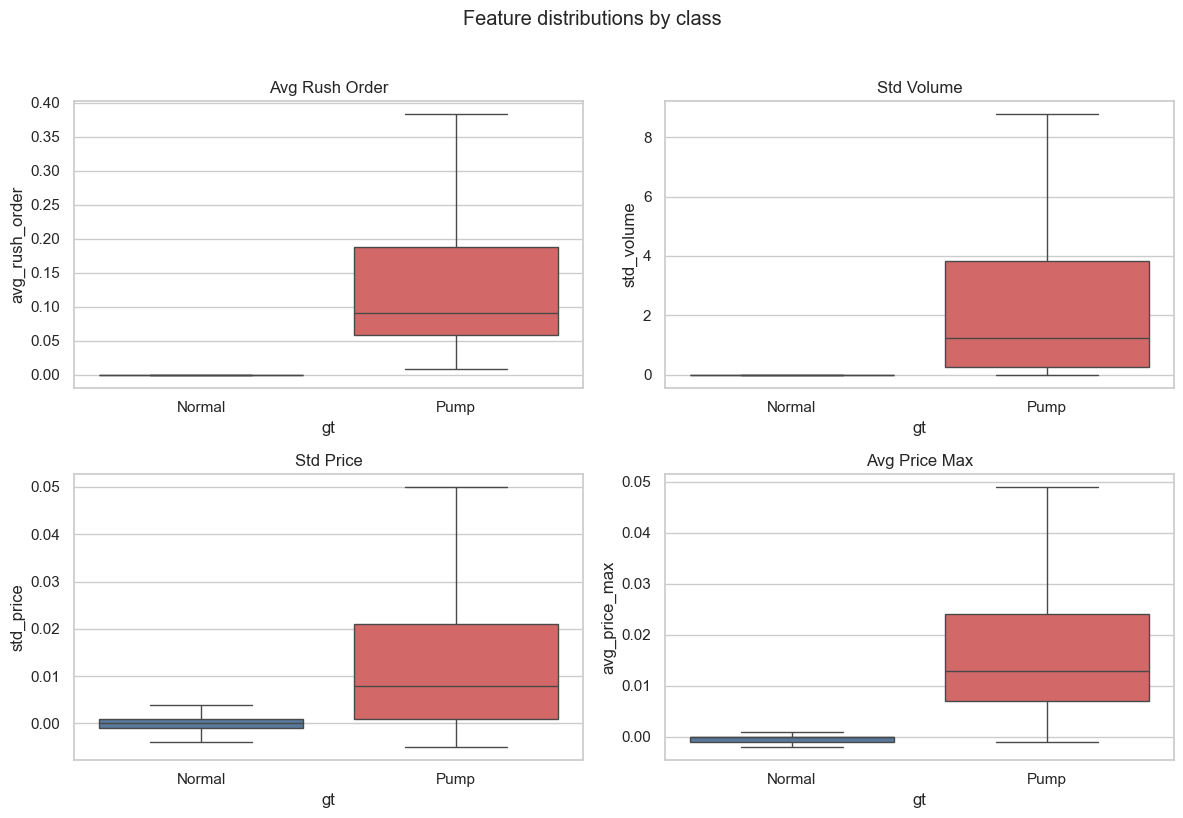

In [20]:
plot_data = data[FEATURES + ['gt']].copy()
plot_data['gt'] = plot_data['gt'].map({0: 'Normal', 1: 'Pump'})
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(['avg_rush_order', 'std_volume', 'std_price', 'avg_price_max'], axes.ravel()):
    sns.boxplot(data=plot_data, x='gt', y=feature, hue='gt', legend=False, palette=['#4C78A8', '#E45756'], showfliers=False, ax=ax)
    ax.set_title(feature.replace('_', ' ').title())
fig.suptitle('Feature distributions by class', y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'feature_distributions.png', dpi=160, bbox_inches='tight')
plt.show()

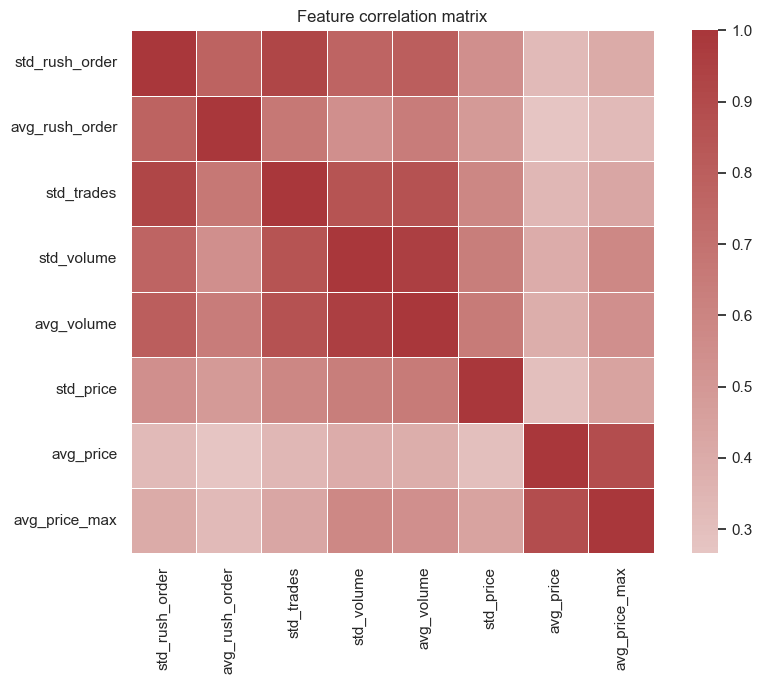

In [21]:
plt.figure(figsize=(9, 7))
sns.heatmap(data[FEATURES].corr(), cmap='vlag', center=0, square=True, linewidths=.4)
plt.title('Feature correlation matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_correlation.png', dpi=160)
plt.show()

The plots are also saved to the project's `output/` folder for use in the progress check.